In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from datetime import datetime
import warnings

warnings.filterwarnings("ignore")

# Define input and output folders
project_folder = Path.cwd().parent

input_folder = project_folder / "dataset"
output_folder = project_folder / "dataset cleaned"

# Create output folder
output_folder.mkdir(parents=True, exist_ok=True)

print("Data Cleaning Project")
print("=====================")
print("Input Folder:", input_folder.resolve())
print("Output Folder:", output_folder.resolve())

Data Cleaning Project
Input Folder: C:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset
Output Folder: C:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned


| Cleaning Operation | Assumption |
|---|---|
| Duplicate Removal | Remove exact duplicate records. |
| Empty Rows | Remove completely empty rows. |
| Empty Columns | Remove completely empty columns. |
| Missing Numerical Values | Replace with median when missingness is 50% or less. |
| Missing Categorical Values | Replace with "Unknown" when missingness is 50% or less. |
| High Missingness | Retain missing values when missingness exceeds 50%. |
| Outliers | Identify using the IQR method, but do not automatically delete. |
| Column Names | Standardize to lowercase with underscores. |
| Original Datasets | Preserve the original Excel files. |

In [12]:
# Find all Excel files inside the dataset folder
excel_files = [
    file for file in input_folder.glob("*.xlsx")
    if not file.name.startswith("~$")
]

print("Excel Files Found:", len(excel_files))

for file in excel_files:
    print("-", file.name)

if not excel_files:
    raise FileNotFoundError("No Excel files found.")

Excel Files Found: 11
- bluz.xlsx
- elbise.xlsx
- etek.xlsx
- gomlek.xlsx
- kaban.xlsx
- kazak.xlsx
- mont.xlsx
- pantolon.xlsx
- sort.xlsx
- sweatshirt.xlsx
- tshirt.xlsx


In [13]:
def clean_dataset(df):

    # Record original number of rows and columns
    original_rows = len(df)
    original_columns = len(df.columns)

    # Remove completely empty rows
    df = df.dropna(how="all")

    # Remove completely empty columns
    df = df.dropna(axis=1, how="all")

    # Remove duplicate rows
    duplicate_count = df.duplicated().sum()
    df = df.drop_duplicates()

    # Standardize column names
    df.columns = (
        df.columns.astype(str)
        .str.strip()
        .str.lower()
        .str.replace(r"\s+", "_", regex=True)
        .str.replace(r"[^a-zA-Z0-9_]", "", regex=True)
    )

    # Ensure column names are unique
    df.columns = pd.Index(df.columns).map(str)

    if df.columns.duplicated().any():
        counts = {}
        new_columns = []

        for column in df.columns:
            counts[column] = counts.get(column, 0) + 1

            if counts[column] > 1:
                new_columns.append(f"{column}_{counts[column]}")
            else:
                new_columns.append(column)

        df.columns = new_columns

    # Clean text values
    for column in df.select_dtypes(include="object").columns:

        df[column] = df[column].astype("string").str.strip()

        # Convert empty strings into missing values
        df[column] = df[column].replace("", pd.NA)

        # Convert common representations of missing values
        df[column] = df[column].replace(
            ["NA", "N/A", "NULL", "null", "None", "nan"],
            pd.NA
        )

    # Handle missing values
    missing_summary = []

    for column in df.columns:

        missing_count = df[column].isna().sum()
        missing_percentage = (
            missing_count / len(df) * 100 if len(df) > 0 else 0
        )

        if missing_count > 0:

            # Fill numerical missing values using median
            if pd.api.types.is_numeric_dtype(df[column]):

                if missing_percentage <= 50:
                    median_value = df[column].median()
                    df[column] = df[column].fillna(median_value)

            # Fill categorical missing values using Unknown
            else:

                if missing_percentage <= 50:
                    df[column] = df[column].fillna("Unknown")

        missing_summary.append({
            "Column": column,
            "Missing Values": missing_count,
            "Missing Percentage": round(missing_percentage, 2)
        })

    # Record final number of rows
    cleaned_rows = len(df)

    # Create cleaning report
    cleaning_report = {
        "Original Rows": original_rows,
        "Cleaned Rows": cleaned_rows,
        "Rows Removed": original_rows - cleaned_rows,
        "Original Columns": original_columns,
        "Cleaned Columns": len(df.columns),
        "Duplicate Rows Removed": duplicate_count
    }

    return df, cleaning_report, pd.DataFrame(missing_summary)

In [14]:
def analyze_outliers(df):

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns

    outlier_summary = []

    for column in numeric_columns:

        # Calculate quartiles
        Q1 = df[column].quantile(0.25)
        Q3 = df[column].quantile(0.75)

        # Calculate Interquartile Range
        IQR = Q3 - Q1

        # Define outlier boundaries
        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        # Identify potential outliers
        outliers = df[
            (df[column] < lower_bound) |
            (df[column] > upper_bound)
        ]

        outlier_summary.append({
            "Column": column,
            "Lower Bound": lower_bound,
            "Upper Bound": upper_bound,
            "Potential Outliers": len(outliers)
        })

    return pd.DataFrame(outlier_summary)

In [15]:
def generate_graphs(df, filename):

    numeric_columns = df.select_dtypes(
        include=np.number
    ).columns

    categorical_columns = df.select_dtypes(
        include=["object", "string", "category"]
    ).columns

    # Graph 1: Missing Values
    missing_data = df.isnull().sum()
    missing_data = missing_data[missing_data > 0]

    if not missing_data.empty:

        plt.figure(figsize=(10, 5))

        missing_data.sort_values().plot(
            kind="bar",
            color="coral"
        )

        plt.title(f"Missing Values - {filename}")
        plt.xlabel("Columns")
        plt.ylabel("Missing Value Count")
        plt.xticks(rotation=45, ha="right")
        plt.tight_layout()
        plt.show()

    # Graph 2: Numerical Distributions
    if len(numeric_columns) > 0:

        df[numeric_columns].hist(
            figsize=(12, 8),
            bins=20,
            edgecolor="black"
        )

        plt.suptitle(
            f"Numerical Data Distribution - {filename}"
        )

        plt.tight_layout()
        plt.show()

    # Graph 3: Outlier Detection
    if len(numeric_columns) > 0:

        plt.figure(figsize=(12, 6))

        sns.boxplot(data=df[numeric_columns])

        plt.title(f"Outlier Analysis - {filename}")
        plt.xticks(rotation=45)
        plt.tight_layout()
        plt.show()

    # Graph 4: Categorical Distribution
    for column in categorical_columns[:5]:

        if df[column].nunique() <= 20:

            plt.figure(figsize=(9, 5))

            df[column].value_counts().head(10).plot(
                kind="bar",
                color="skyblue"
            )

            plt.title(
                f"{column} Distribution - {filename}"
            )

            plt.xlabel(column)
            plt.ylabel("Frequency")
            plt.xticks(rotation=45, ha="right")
            plt.tight_layout()
            plt.show()


PROCESSING: bluz.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


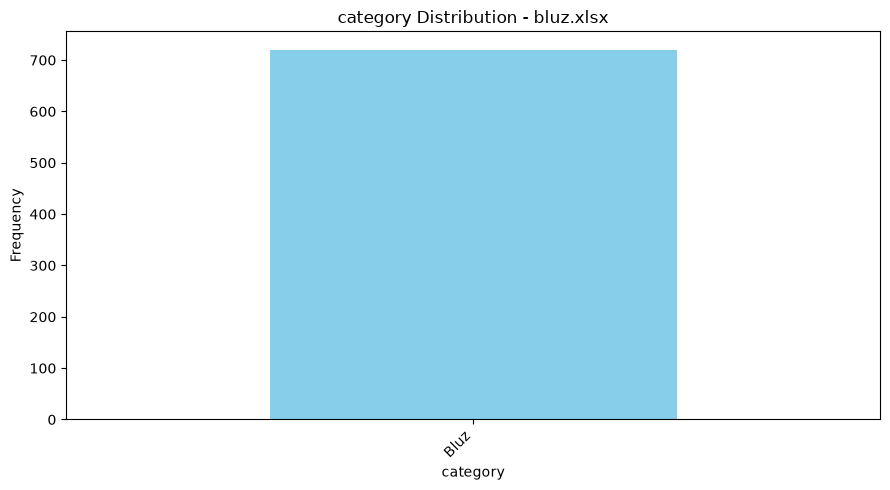


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\bluz_cleaned.xlsx

PROCESSING: elbise.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 120
Cleaned Rows: 120
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


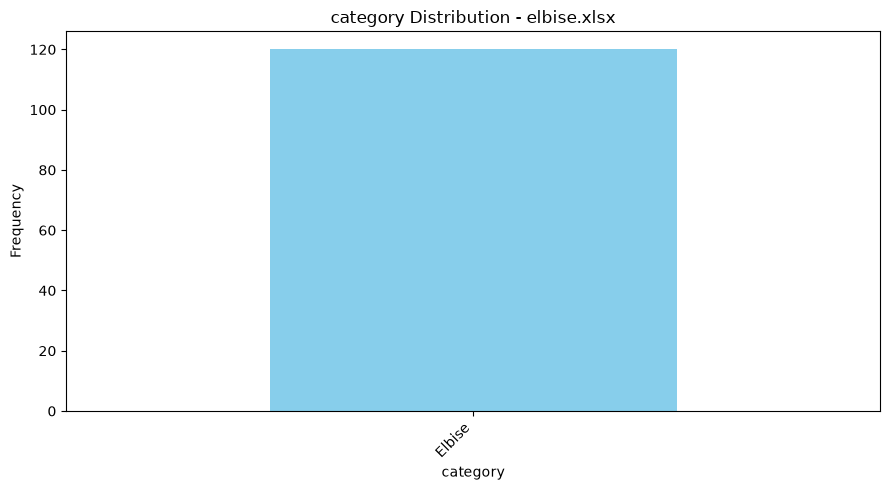


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\elbise_cleaned.xlsx

PROCESSING: etek.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


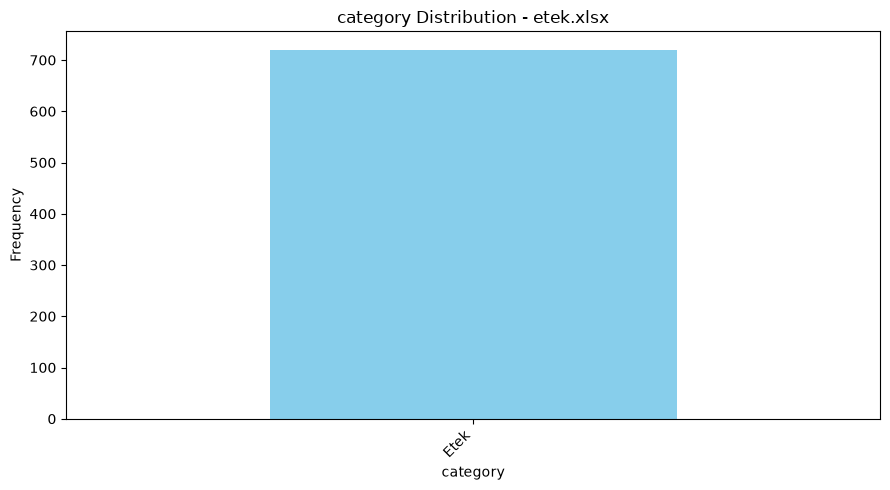


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\etek_cleaned.xlsx

PROCESSING: gomlek.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


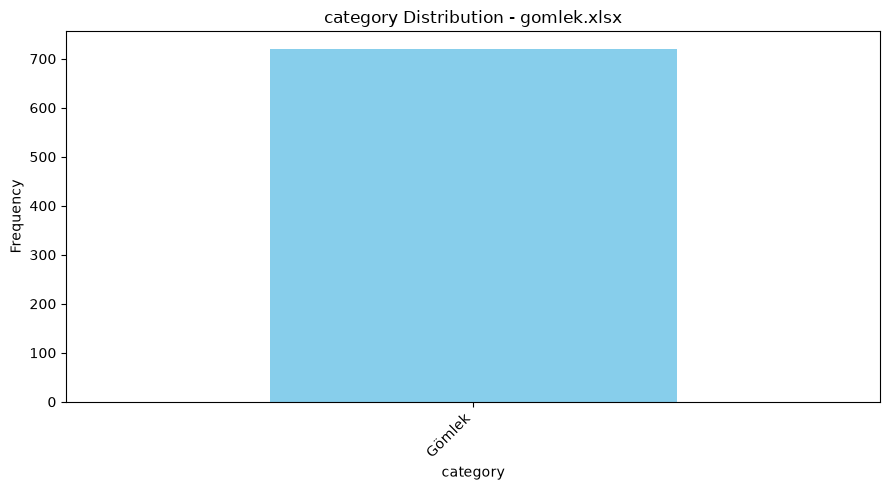


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\gomlek_cleaned.xlsx

PROCESSING: kaban.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


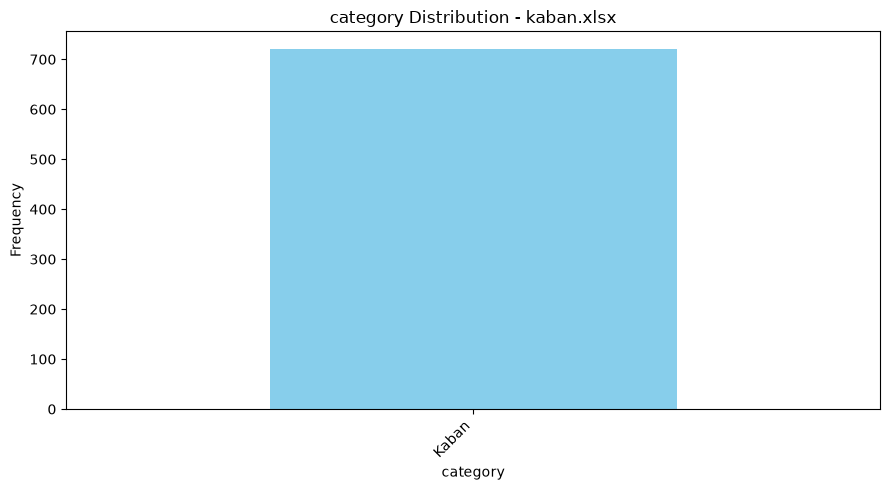


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\kaban_cleaned.xlsx

PROCESSING: kazak.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


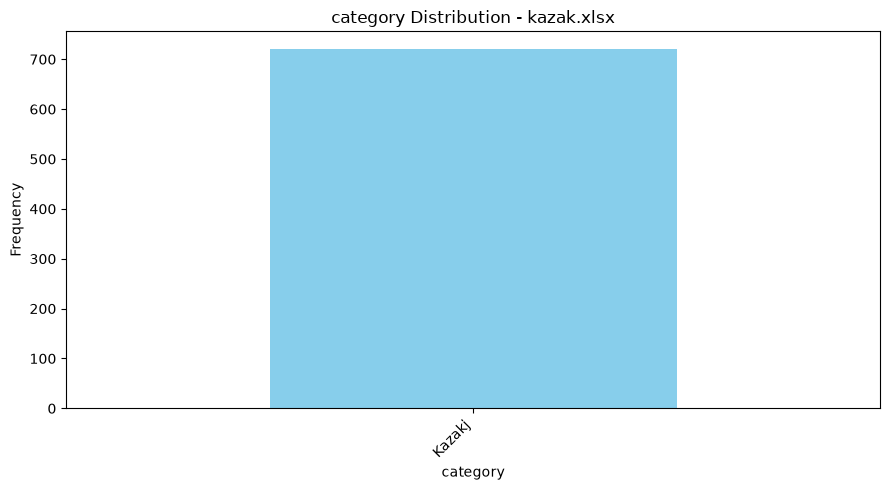


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\kazak_cleaned.xlsx

PROCESSING: mont.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


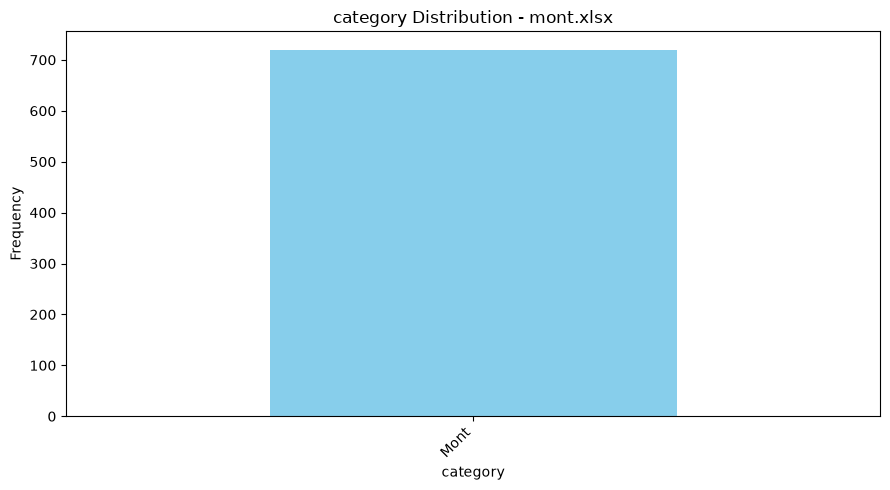


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\mont_cleaned.xlsx

PROCESSING: pantolon.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


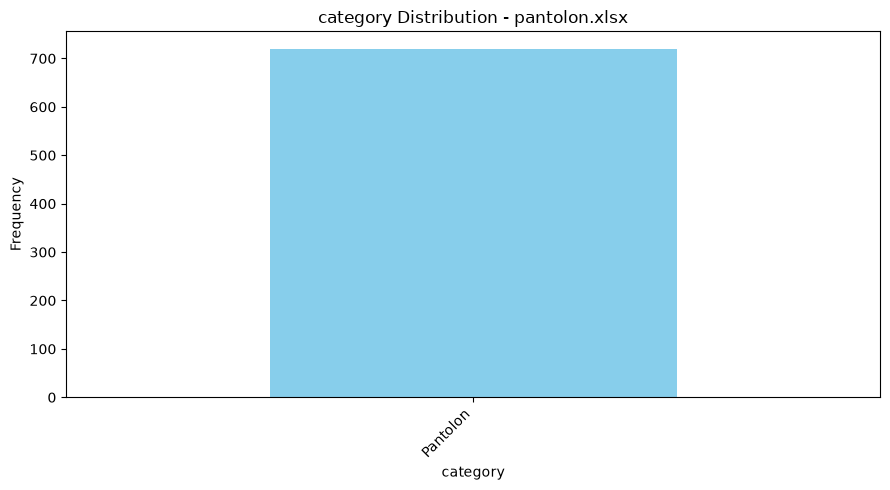


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\pantolon_cleaned.xlsx

PROCESSING: sort.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


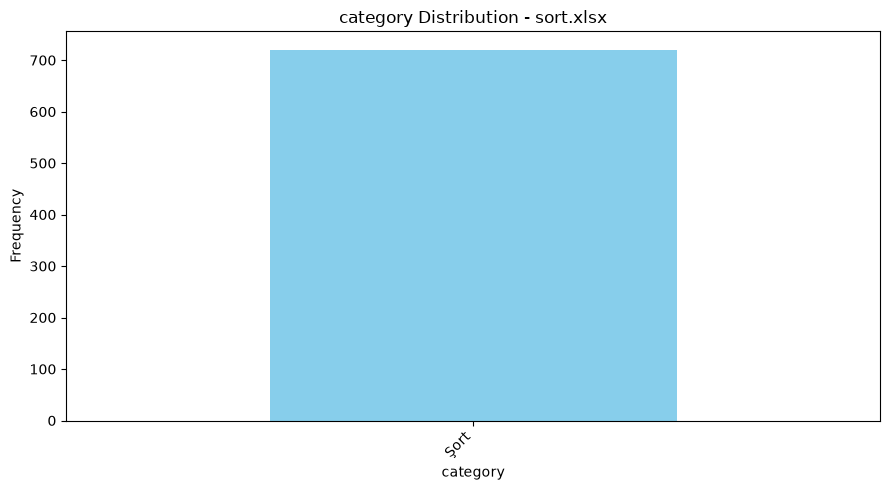


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\sort_cleaned.xlsx

PROCESSING: sweatshirt.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


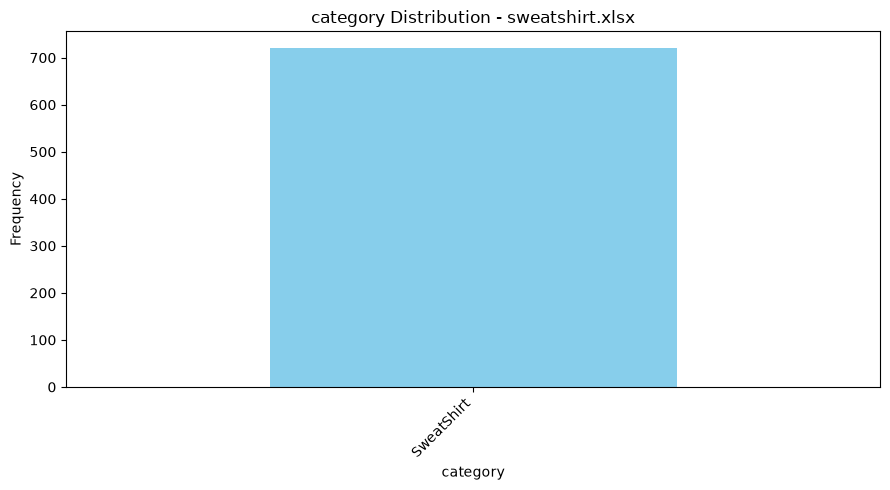


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\sweatshirt_cleaned.xlsx

PROCESSING: tshirt.xlsx

Worksheet: Sheet1

CLEANING SUMMARY
Original Rows: 720
Cleaned Rows: 720
Rows Removed: 0
Original Columns: 5
Cleaned Columns: 5
Duplicate Rows Removed: 0

MISSING VALUE ANALYSIS


,Column,Missing Values,Missing Percentage
0,image_url,0,0.0
1,price,0,0.0
2,brand,0,0.0
3,category,0,0.0
4,image_name,0,0.0



OUTLIER ANALYSIS


""



DATA VISUALIZATIONS


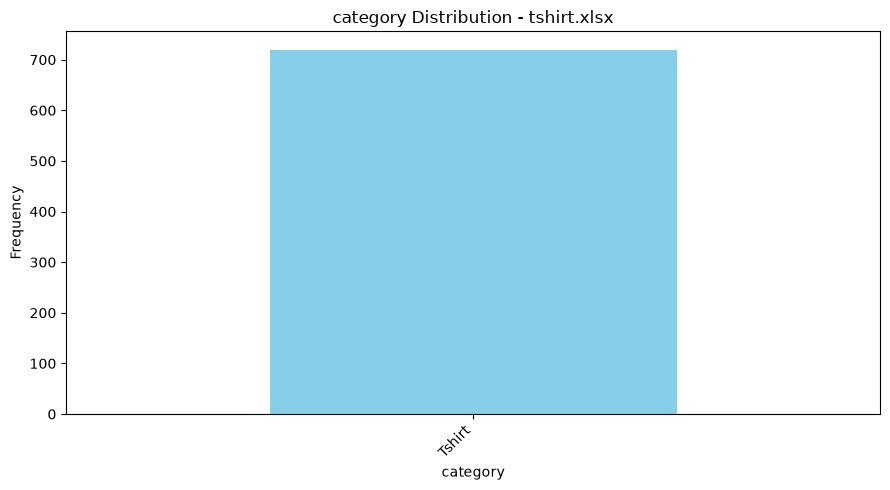


SAVED CLEANED WORKBOOK:
c:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned\tshirt_cleaned.xlsx

ALL DATASETS PROCESSED SUCCESSFULLY!


In [16]:
# Store results from all processed workbooks
overall_results = []

# Process each Excel workbook
for file in excel_files:

    print("\n" + "=" * 60)
    print("PROCESSING:", file.name)
    print("=" * 60)

    # Read all worksheets
    sheets = pd.read_excel(file, sheet_name=None)

    cleaned_sheets = {}

    workbook_reports = []

    # Process each worksheet
    for sheet_name, original_df in sheets.items():

        print("\nWorksheet:", sheet_name)

        # Clean the worksheet
        cleaned_df, report, missing_summary = clean_dataset(
            original_df.copy()
        )

        # Analyze potential outliers
        outlier_summary = analyze_outliers(cleaned_df)

        # Display cleaning results
        print("\nCLEANING SUMMARY")

        for key, value in report.items():
            print(f"{key}: {value}")

        # Display missing value information
        print("\nMISSING VALUE ANALYSIS")

        display(missing_summary)

        # Display outlier information
        print("\nOUTLIER ANALYSIS")

        display(outlier_summary)

        # Generate visualizations
        print("\nDATA VISUALIZATIONS")

        generate_graphs(cleaned_df, file.name)

        # Store cleaned worksheet
        cleaned_sheets[sheet_name] = cleaned_df

        # Store worksheet report
        report["File"] = file.name
        report["Worksheet"] = sheet_name

        workbook_reports.append(report)

        overall_results.append(report)

    # Export cleaned workbook
    output_file = output_folder / f"{file.stem}_cleaned.xlsx"

    with pd.ExcelWriter(output_file, engine="openpyxl") as writer:

        # Save cleaned worksheets
        for sheet_name, cleaned_df in cleaned_sheets.items():

            safe_sheet_name = sheet_name[:31]

            cleaned_df.to_excel(
                writer,
                sheet_name=safe_sheet_name,
                index=False
            )

        # Add cleaning summary worksheet
        summary_df = pd.DataFrame(workbook_reports)

        summary_df.to_excel(
            writer,
            sheet_name="Cleaning Summary",
            index=False
        )

    print("\nSAVED CLEANED WORKBOOK:")
    print(output_file)

print("\nALL DATASETS PROCESSED SUCCESSFULLY!")

In [17]:
# Create overall cleaning report
overall_summary = pd.DataFrame(overall_results)

print("OVERALL DATA CLEANING RESULTS")
print("=" * 60)

display(overall_summary)

# Calculate total records before and after cleaning
total_original = overall_summary["Original Rows"].sum()
total_cleaned = overall_summary["Cleaned Rows"].sum()
total_removed = overall_summary["Rows Removed"].sum()

print("\nFINAL RESULTS")
print("=" * 60)

print("Total Original Rows:", total_original)
print("Total Cleaned Rows:", total_cleaned)
print("Total Rows Removed:", total_removed)

if total_original > 0:

    removal_percentage = (
        total_removed / total_original
    ) * 100

    print(
        "Overall Row Removal Percentage:",
        round(removal_percentage, 2), "%"
    )

print(
    "\nCleaned files saved in:",
    output_folder.resolve()
)

OVERALL DATA CLEANING RESULTS


,Original Rows,Cleaned Rows,Rows Removed,Original Columns,Cleaned Columns,Duplicate Rows Removed,File,Worksheet
0,720,720,0,5,5,0,bluz.xlsx,Sheet1
1,120,120,0,5,5,0,elbise.xlsx,Sheet1
2,720,720,0,5,5,0,etek.xlsx,Sheet1
3,720,720,0,5,5,0,gomlek.xlsx,Sheet1
4,720,720,0,5,5,0,kaban.xlsx,Sheet1
5,720,720,0,5,5,0,kazak.xlsx,Sheet1
6,720,720,0,5,5,0,mont.xlsx,Sheet1
7,720,720,0,5,5,0,pantolon.xlsx,Sheet1
8,720,720,0,5,5,0,sort.xlsx,Sheet1
9,720,720,0,5,5,0,sweatshirt.xlsx,Sheet1



FINAL RESULTS
Total Original Rows: 7320
Total Cleaned Rows: 7320
Total Rows Removed: 0
Overall Row Removal Percentage: 0.0 %

Cleaned files saved in: C:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned


In [18]:
# Create overall cleaning report
overall_summary = pd.DataFrame(overall_results)

print("OVERALL DATA CLEANING RESULTS")
print("=" * 60)

display(overall_summary)

# Calculate total records before and after cleaning
total_original = overall_summary["Original Rows"].sum()
total_cleaned = overall_summary["Cleaned Rows"].sum()
total_removed = overall_summary["Rows Removed"].sum()

print("\nFINAL RESULTS")
print("=" * 60)

print("Total Original Rows:", total_original)
print("Total Cleaned Rows:", total_cleaned)
print("Total Rows Removed:", total_removed)

if total_original > 0:

    removal_percentage = (
        total_removed / total_original
    ) * 100

    print(
        "Overall Row Removal Percentage:",
        round(removal_percentage, 2), "%"
    )

print(
    "\nCleaned files saved in:",
    output_folder.resolve()
)

OVERALL DATA CLEANING RESULTS


,Original Rows,Cleaned Rows,Rows Removed,Original Columns,Cleaned Columns,Duplicate Rows Removed,File,Worksheet
0,720,720,0,5,5,0,bluz.xlsx,Sheet1
1,120,120,0,5,5,0,elbise.xlsx,Sheet1
2,720,720,0,5,5,0,etek.xlsx,Sheet1
3,720,720,0,5,5,0,gomlek.xlsx,Sheet1
4,720,720,0,5,5,0,kaban.xlsx,Sheet1
5,720,720,0,5,5,0,kazak.xlsx,Sheet1
6,720,720,0,5,5,0,mont.xlsx,Sheet1
7,720,720,0,5,5,0,pantolon.xlsx,Sheet1
8,720,720,0,5,5,0,sort.xlsx,Sheet1
9,720,720,0,5,5,0,sweatshirt.xlsx,Sheet1



FINAL RESULTS
Total Original Rows: 7320
Total Cleaned Rows: 7320
Total Rows Removed: 0
Overall Row Removal Percentage: 0.0 %

Cleaned files saved in: C:\Users\fluffymammon\Desktop\Capstone\Data Cleaning\dataset cleaned


<Figure size 1200x600 with 0 Axes>

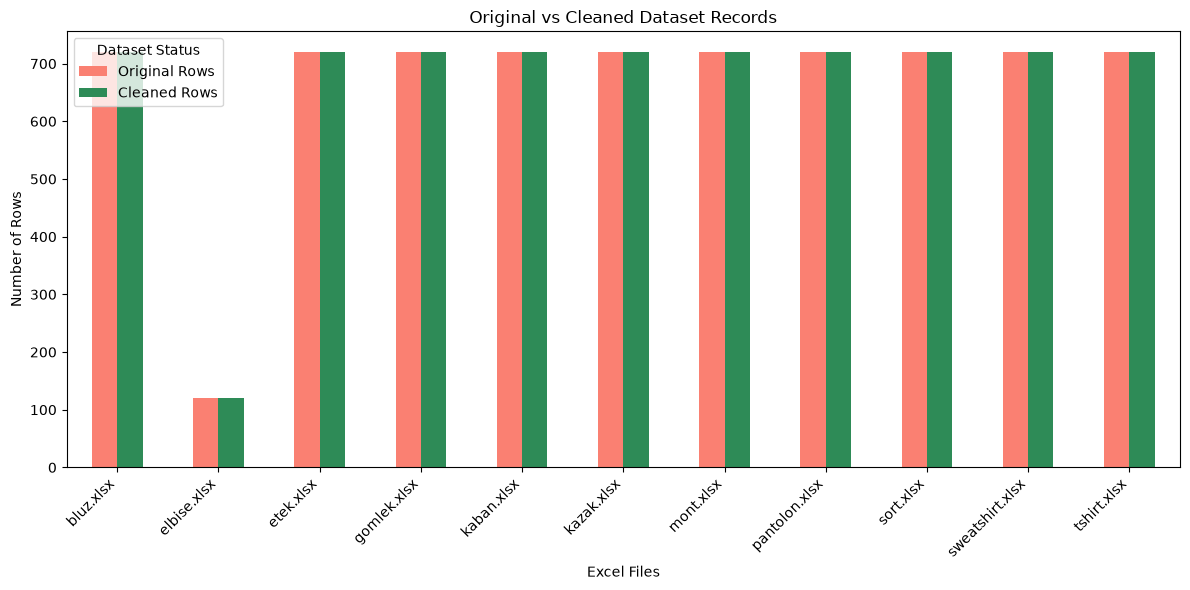

In [19]:
# Compare original and cleaned row counts
plt.figure(figsize=(12, 6))

comparison = overall_summary.set_index(
    "File"
)[["Original Rows", "Cleaned Rows"]]

comparison.plot(
    kind="bar",
    figsize=(12, 6),
    color=["salmon", "seagreen"]
)

plt.title("Original vs Cleaned Dataset Records")
plt.xlabel("Excel Files")
plt.ylabel("Number of Rows")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Dataset Status")
plt.tight_layout()
plt.show()